## Importy i Wczytanie Danych

In [42]:
%load_ext autoreload
%autoreload 2

import sys
import os
sys.path.append(os.path.abspath('..'))
from src.loader import load_data
from src.preprocess import get_subject_split, map_class
from src.visualizations import plot_correlation_matrix, plot_band_power, plot_box
from src.features import build_dataset

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [43]:
# najpierw ładujemy zbiór, zobaczymy informacje o kolumnach
data_raw = load_data("../data/adhdata.csv")
data_raw.shape
data_raw.info()
print(f"Liczba braków danych: {(data_raw.isna().sum()).sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 2166383 entries, 0 to 2166382
Data columns (total 21 columns):
 #   Column  Dtype  
---  ------  -----  
 0   Fp1     float64
 1   Fp2     float64
 2   F3      float64
 3   F4      float64
 4   C3      float64
 5   C4      float64
 6   P3      float64
 7   P4      float64
 8   O1      float64
 9   O2      float64
 10  F7      float64
 11  F8      float64
 12  T7      float64
 13  T8      float64
 14  P7      float64
 15  P8      float64
 16  Fz      float64
 17  Cz      float64
 18  Pz      float64
 19  Class   str    
 20  ID      str    
dtypes: float64(19), str(2)
memory usage: 347.1 MB
Liczba braków danych: 0


Mamy 19 kolumn, będących odczytami sygnałów z różnych czujników, kolumnę z ID oraz informację, czy pacjent ma ADHD, czy nie. Pomiary zebrano z elektrod rozmieszczonych w systemie 10-20, czyli w odstępach 10% do 20% odległości na czaszce.
Elektrody rozmieszczane są w nast. lokalizacjach:
+ F - płat czołowy
+ C - płat centralny
+ T - płat skroniowy
+ P - płat ciemienowy / ciemieniowo-skroniowy
+ O - płat potyliczny


Nie ma w tym zbiorze brakujących danych. Zmapujemy teraz kolumnę targetową oraz wykonamy podział na zbiór treningowy i testowy. Złączymy także zbiór cech ze zbiorem klas dla danych treningowych.

In [44]:
data_mapped = map_class(data_raw)
X_train, X_test, y_train, y_test = get_subject_split(data=data_mapped)
eda_df = X_train.copy()
eda_df['Class'] = y_train

## Analiza surowych sygnałów

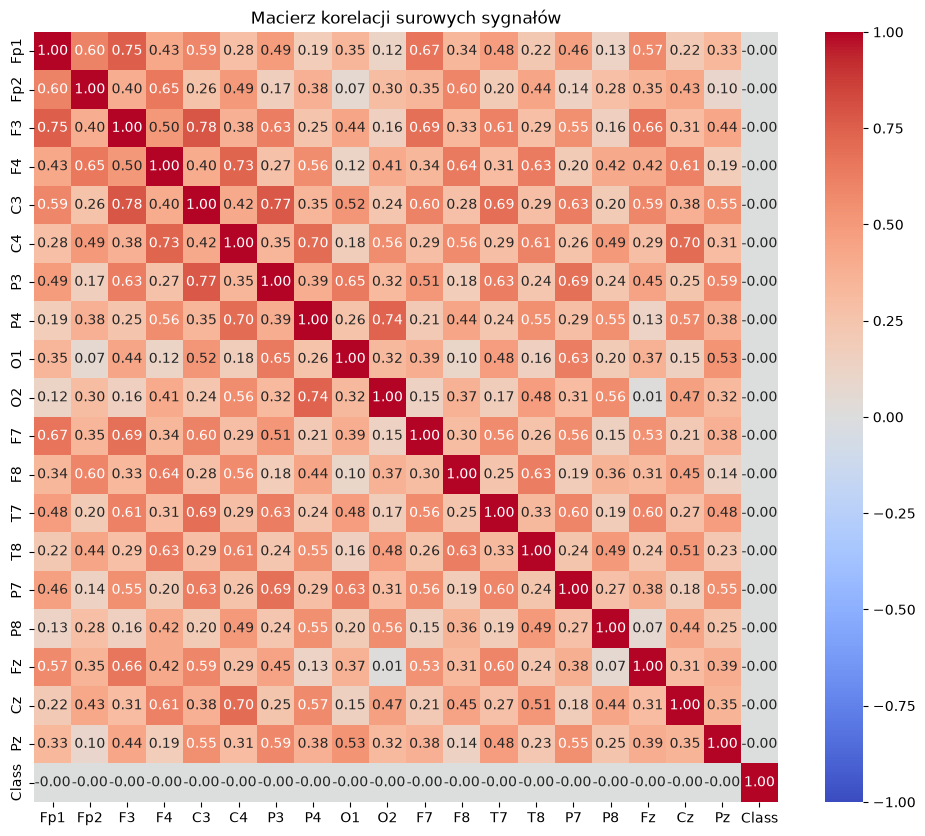

In [45]:
plot_correlation_matrix(eda_df, title="Macierz korelacji surowych sygnałów")

Korelacja surowych sygnałów z występowaniem ADHD jest zerowa - dodatkowo, modele niegłębokie, z jakich zamierzam korzystać, nie potrafią raczej przeanalizować szeregów czasowych dla jednej osoby i jeszcze jakoś ich ze sobą powiązać. Trzeba więc mocno przerobić nasze dane, by faktycznie stanowiły jakieś cechy dla jednej osoby. 


## Przekształcenie zbioru danych

Podczas researchu, dowiedziałem się m. in. [stąd](https://akson-edu.pl/adhd-u-doroslych-qeeg/), że najważniejszy w klasyfikacji ADHD jest współczynnik fal beta/theta. Fale theta, krótsze (4-8 hz) odpowiadają za stan rozproszenia, natomiast beta (12 - 30 hz) za skupienie i koncentrację. U osób z ADHD mamy właśnie większą aktywność theta przy mniejszej beta. Rolę mogą również odgrywać podwyższona bezwzględną moc fal delta w okolicach czołowych oraz podwyższony wskaźnik asymetrii czołowej. W związku z tym, nasze surowe sygnały przerobimy właśnie na te wskaźniki. Ważne jest jednak to, że pacjencji leczeni byli Ritalinem - lekiem używanym własnie przy leczeniu ADHD, który poprawia koncentrację, zmniejsza impulsywnosć i nadmierną ruchliwosć. Być może przez to, nasze wskaźniki nie będą aż tak skorelowane z ADHD, mogą być nawet lepsze u pacjentów niż u grupy kontrolnej.

Sygnały EEG przekształcimy na sygnały dla danych częstotliwosci za pomocą metody Welcha.
Długosć segmentu ustawiamy na 128, co daje optymalną rozdzielczosć równą 1 Hz.
Z każdego kanału wyliczamy średnią bezwzględną moc w czterech standardowych pasmach QEEG: Delta (0.5-4 Hz), Theta (4-8 Hz), Alpha (8-13 Hz) oraz Beta (13-30 Hz).

Biorąc po samym ID, dostalibyśmy tylko 121 wierszy, jest małą ilością danych. Sygnały od każdej z osób podzielę więc na interwały dwusekundowe. W ten sposób powstanie kilka tysięcy przykładów do nauczenia modeli.

In [46]:
df_features = build_dataset(eda_df)

<class 'pandas.DataFrame'>
RangeIndex: 6732 entries, 0 to 6731
Data columns (total 99 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Fz_Delta         6732 non-null   float64
 1   Fz_Theta         6732 non-null   float64
 2   Fz_Alpha         6732 non-null   float64
 3   Fz_Beta          6732 non-null   float64
 4   Fz_TBR           6732 non-null   float64
 5   Cz_Delta         6732 non-null   float64
 6   Cz_Theta         6732 non-null   float64
 7   Cz_Alpha         6732 non-null   float64
 8   Cz_Beta          6732 non-null   float64
 9   Cz_TBR           6732 non-null   float64
 10  Pz_Delta         6732 non-null   float64
 11  Pz_Theta         6732 non-null   float64
 12  Pz_Alpha         6732 non-null   float64
 13  Pz_Beta          6732 non-null   float64
 14  Pz_TBR           6732 non-null   float64
 15  C3_Delta         6732 non-null   float64
 16  C3_Theta         6732 non-null   float64
 17  C3_Alpha         6732 non

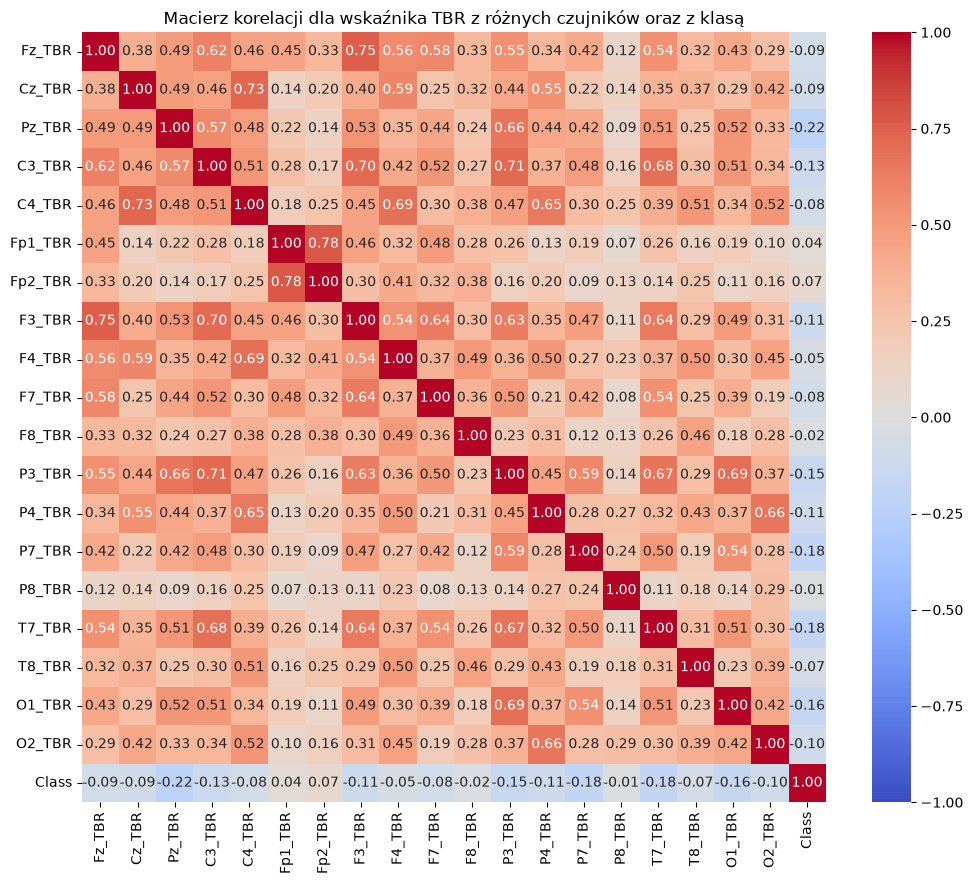

In [47]:
df_features.info()
plot_correlation_matrix(df_features, sufix="_TBR", title="Macierz korelacji dla wskaźnika TBR z różnych czujników oraz z klasą")

Na wykresie korelacji, pomiędzy wskaźnikami TBR dla konkrentych kanałów a tym, czy pacjent ma ADHD czy nie, występuje malutka korelacja. Zazwyczaj jest ona ujemna, co może potwierdzać wyniki działania Ritalinu - poprawił on koncentrację pacjentów. Do wychwycenia ADHD zatem mogą przydać się bardziej skomplikowane modele, bo nie mamy tutaj prostej korelacji liniowej.

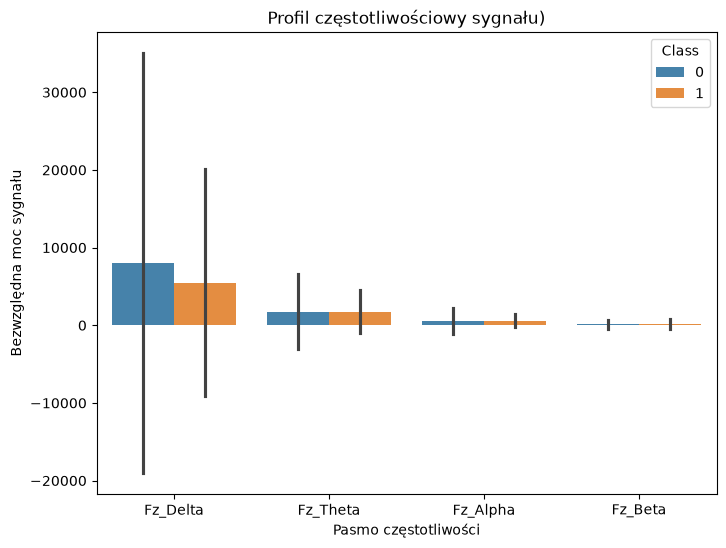

In [39]:
plot_band_power(df_features)

Bezwzględna moc sygnału dla wszystkich fal oprócz delty zdaje się podobna, fale delta natomiast u dzieci z ADHD są obniżone, co znowu może wynikać ze wspomnianego leczenia Ritalinem.

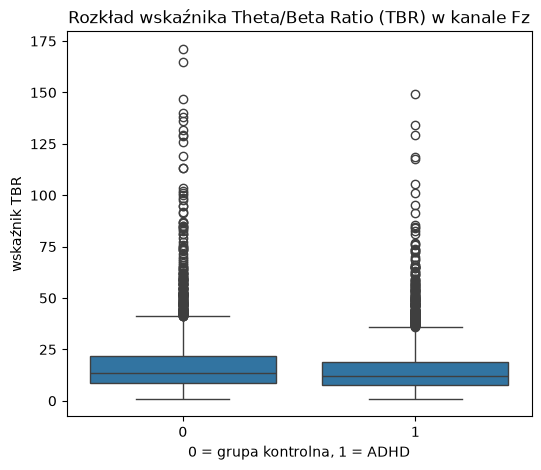

In [33]:
plot_box(df_features)

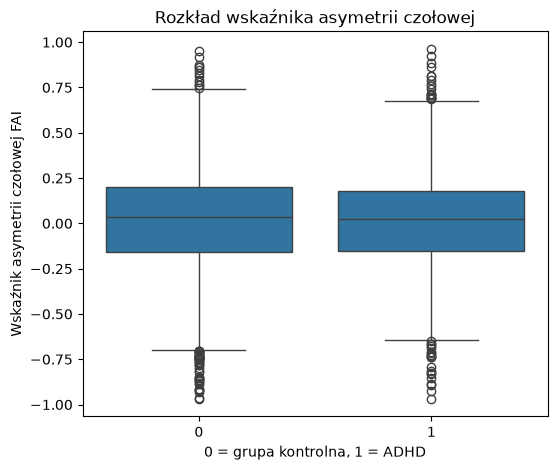

In [36]:
plot_box(df_features, y = 'FAI_Alpha_F4_F3', title="Rozkład wskaźnika asymetrii czołowej",
        ylabel = "Wskaźnik asymetrii czołowej FAI")

Porównując wykresy pudełkowe, widzimy że zarówno dla wskaźnika TBR dla centralnej częsci płatu czołowego jak i dla wskaźnika asymetrii czołowej, mediana jest minimalnie niższa dla dzieci z ADHD. Jednak różnice są na tyle subtelne, że opieranie się na jednym wskaźniku nie wystarcza. Analizę działania różnych modeli przedstawię w notatniku "models.ipynb".